# 09. Decentralized Social Blind Relay, Private Feed & Web-of-Trust (`Bitcoin Lightning L402`)

Copyright 2026 Blind Labs (https://blindlabs.ai). Licensed under the Apache License, Version 2.0.

## Executive Summary (For VCs, Grant Reviewers & Executives)

### What problem does this solve?
Decentralized social protocols like **Nostr** (aligned with Jack Dorsey's open-protocol
social vision) give users censorship-resistant keys, but face an unsolved trilemma:
public relays leak social graphs and DM metadata, algorithmic spam filtering requires
reading plaintext posts on a centralized server, and Sybil spam overwhelms free relays.

### Why can't AWS, legacy FHE, or hardware TEEs do this?
- **Centralized Social Cloud (AWS / X / Traditional Relays)**: Sees every user's plaintext
  posts, follow graph, and message sizes; creates a single choke point for surveillance,
  algorithmic manipulation, and ad-tech profiling.
- **Legacy General-Purpose FHE**: Ranking a user's timeline or computing encrypted
  Web-of-Trust (`WoT`) reputation scores in legacy FHE takes tens of seconds per scroll --
  unusable for consumer social feeds.
- **Hardware TEEs**: Relay operators still control the host OS and can observe packet-size
  fingerprints unless uniform padding and cryptographic cohort bounds are enforced.
- **BlindCore**: Turns any Nostr relay into a **zero-plaintext Blind Relay** monetized via
  **Bitcoin Lightning `L402` sats** (`1 sat` ingest, `8 sats` WoT cohort tally, `30 sats`
  encrypted `SKLEARN_MNB` anti-spam feed ranker):
  1. **Uniform `512 B` dummy-padded envelopes** defeat message-length traffic analysis.
  2. **Private `SKLEARN_MNB` ranking** promotes signal notes and suppresses scam/spam without
     ever decrypting post text.
  3. **`k_min_tkms = 5` stalker guard** blocks single-target WoT deanonymization (`HTTP 422`,
     `0 sats` settled) + **`O(1)` cryptographic Right-to-Delete**.

### End-to-End Architecture

```text
+--------------------------+  1. Dummy-padded 512 B events   +---------------------------+
| Nostr Client / Keypair   | ------------------------------> | BlindCore Tri-Rail Gate   |
| (Lightning L402 Wallet)  | <--- HTTP 402 BOLT11 invoice -- |  * INGEST      :  1 sat   |
|                          | ---- Authorization: L402 -----> |  * WoT Tally   :  8 sats  |
| Local npub/nsec keys     |      <macaroon>:<preimage>      |  * MNB Ranker  : 30 sats  |
|  * Pads all notes -> 512B|                                 |  * Replay block: HTTP 402 |
|  * Never reveals content |                                 |  * Stalker k<5 : HTTP 422 |
+--------------------------+                                 +-------------+-------------+
                                                                           |
                                                                           v
                                                             +---------------------------+
                                                             | BlindCore Blind Relay     |
                                                             |  * FEED_PROMOTE vs SPAM   |
                                                             |  * WoT Cohort >= 5 only   |
                                                             |  * O(1) Right-to-Delete   |
                                                             |  * L402-PREIMAGE-HTLC-V2  |
                                                             +---------------------------+
```


In [1]:
import base64
import json
import urllib.error
import urllib.request

GATE_URL = "https://api.blindlabs.ai/testnet"
PROBE_PATH = "/api/v1/blind/jsonb/query"
PROBE_PAYLOAD = {"op": "WEIGHTED_SUM", "table": "tbl_nostr_blind_relay_probe"}

req = urllib.request.Request(
    GATE_URL + PROBE_PATH,
    data=json.dumps(PROBE_PAYLOAD).encode("utf-8"),
    headers={"Content-Type": "application/json", "User-Agent": "BlindCore-Investor-Notebook/1.0"},
    method="POST",
)

probe_status = 0
probe_headers = {}
probe_body = {}
try:
    with urllib.request.urlopen(req, timeout=15) as resp:
        probe_status = int(resp.status)
        probe_headers = dict(resp.headers.items())
        probe_body = json.loads(resp.read().decode("utf-8"))
except urllib.error.HTTPError as exc:
    probe_status = int(exc.code)
    probe_headers = dict(exc.headers.items())
    probe_body = json.loads(exc.read().decode("utf-8"))

hdr_lower = {k.lower(): v for k, v in probe_headers.items()}
assert probe_status == 402, f"Expected live HTTP 402 quote, got {probe_status}"
assert "payment-required" in hdr_lower, "Missing x402 v2 PAYMENT-REQUIRED header"
assert "www-authenticate" in hdr_lower, "Missing Lightning L402 WWW-Authenticate header"
assert "x-stacks-payment-required" in hdr_lower, "Missing Stacks sBTC header"

x402_quote = json.loads(base64.b64decode(hdr_lower["payment-required"]).decode("utf-8"))
stacks_quote = json.loads(base64.b64decode(hdr_lower["x-stacks-payment-required"]).decode("utf-8"))
l402_hdr = hdr_lower["www-authenticate"]
bazaar = x402_quote.get("extensions", {}).get("bazaar", {})
first_accept = x402_quote["accepts"][0]

print("=== LIVE TESTNET HTTP 402 TRI-RAIL PROBE (Bitcoin Lightning L402) ===")
print(f"Endpoint                : POST {GATE_URL}{PROBE_PATH}")
print(f"HTTP Status             : {probe_status} Payment Required")
print(f"x402 Version            : v{x402_quote.get('x402Version')}")
print(f"Bazaar Discoverable     : {bazaar.get('discoverable')} (category={bazaar.get('category')}, SLA={bazaar.get('latencySlaMs')} ms)")
print(f"Rail 1 (Base x402 USDC) : network={first_accept['network']}, amount={first_accept['amount']} micro-USDC (${int(first_accept['amount'])/1_000_000:.4f})")
print(f"Rail 2 (Lightning L402) : {l402_hdr[:68]}... [{x402_quote['extensions']['lightning_l402']['sats']} sats]")
print(f"Rail 3 (Stacks sBTC)    : network={stacks_quote['network']}, amount={stacks_quote['amountSats']} sats, contract={stacks_quote['sbtcContract']}")


=== LIVE TESTNET HTTP 402 TRI-RAIL PROBE (Bitcoin Lightning L402) ===
Endpoint                : POST https://api.blindlabs.ai/testnet/api/v1/blind/jsonb/query
HTTP Status             : 402 Payment Required
x402 Version            : v2
Bazaar Discoverable     : True (category=confidential-compute, SLA=25 ms)
Rail 1 (Base x402 USDC) : network=eip155:84532, amount=5000 micro-USDC ($0.0050)
Rail 2 (Lightning L402) : L402 macaroon="eyJjYXZlYXRzIjpbInRpZXI9U1VNIiwic2F0cz04IiwicGF0aD0vY... [8 sats]
Rail 3 (Stacks sBTC)    : network=stacks:testnet, amount=8 sats, contract=ST1F7QA2MDF17S807EPA36TSS8AMEFY4KA9TVGWXT.sbtc-token


In [2]:
import json
import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from apps.app04_nostr_blind_relay import run_demo

result = run_demo(mode="local")
assert result["status"] == "PASS", f"App 04 failed: {result}"
assert result["zero_plaintext_verified"] is True
assert result["http_402_observed"] is True
assert result["counterfactual_knockout_verified"] is True

sm = result["summary"]
wire = result["wire_sample_redacted"]
sp = result["settle_proof"]
feed = sm["private_feed_ranker_mnb"]
wot = sm["encrypted_wot_cohort_tally"]
stalker = sm["wot_stalker_guard"]
rtd = sm["o1_right_to_delete_shred"]

rows = [
    ("Application", result["title"]),
    ("Status", result["status"]),
    ("Payment Rail", f"{result['rail']} ({sp['network']}, {sp['scheme']})"),
    ("E2E Local Run Time", f"{result['elapsed_ms']:.2f} ms"),
    ("HTTP 402 / L402 Replay", f"http_402={result['http_402_observed']} | replay_status=HTTP {sm['l402_replay_http_status']}"),
    ("Traffic-Analysis Defense", f"{sm['dummy_padded_events_ingested']} events padded to uniform {sm['uniform_envelope_bytes']} B ({sm['uniform_slot_count']} slots)"),
    ("Zero Plaintext Verified", f"{result['zero_plaintext_verified']} ({wire['plaintext_leaks_found']} leaks / {wire['wire_bytes_audited']:,} wire bytes)"),
    ("Private Feed Ranker MNB", f"{feed['sats_paid']} sats | signal={feed['signal_note_verdict']} | scam={feed['scam_note_verdict']}"),
    ("Encrypted WoT Cohort", f"{wot['sats_paid']} sats | cohort={wot['cohort_size']} (k_min={wot['k_min_tkms']}) | trust={wot['wot_trust_score_bps']} bps"),
    ("WoT Stalker Guard (k<5)", f"HTTP {stalker['http_status']} (settlement={stalker['settlement_header']}, leak={stalker['plaintext_leaked']})"),
    ("O(1) Right-to-Delete", f"complexity={rtd['complexity']} | key_dropped={rtd['key_dropped']} | undecryptable={rtd['ciphertext_undecryptable']}"),
    ("NSAU0001 Receipt (96 B)", result["nsau0001_receipt_hex"][:48] + "..."),
    ("L402 Preimage Digest", f"{sp['settle_digest'][:34]}... (sha256_ok={sp['preimage_sha256_verified']})"),
]

w_k = max(len("Audit Metric"), *(len(k) for k, _ in rows))
w_v = max(len("Verified Live Value"), *(len(v) for _, v in rows))
sep = f"+-{'-' * w_k}-+-{'-' * w_v}-+"
print(sep)
print(f"| {'Audit Metric':<{w_k}} | {'Verified Live Value':<{w_v}} |")
print(sep)
for k, v in rows:
    print(f"| {k:<{w_k}} | {v:<{w_v}} |")
print(sep)

print("\n--- Redacted Wire Ciphertext Sample (Uniform 512 B, 0 Plaintext) ---")
print(json.dumps(wire, indent=2))


+--------------------------+-------------------------------------------------------------------------------------+
| Audit Metric             | Verified Live Value                                                                 |
+--------------------------+-------------------------------------------------------------------------------------+
| Application              | Decentralized Social Blind Relay, Private Algorithmic Feed & Encrypted Web-of-Trust |
| Status                   | PASS                                                                                |
| Payment Rail             | ln-l402 (bitcoin:lightning, L402-PREIMAGE-HTLC-V2)                                  |
| E2E Local Run Time       | 206.24 ms                                                                           |
| HTTP 402 / L402 Replay   | http_402=True | replay_status=HTTP 402                                              |
| Traffic-Analysis Defense | 6 events padded to uniform 512 B (6 slots)         

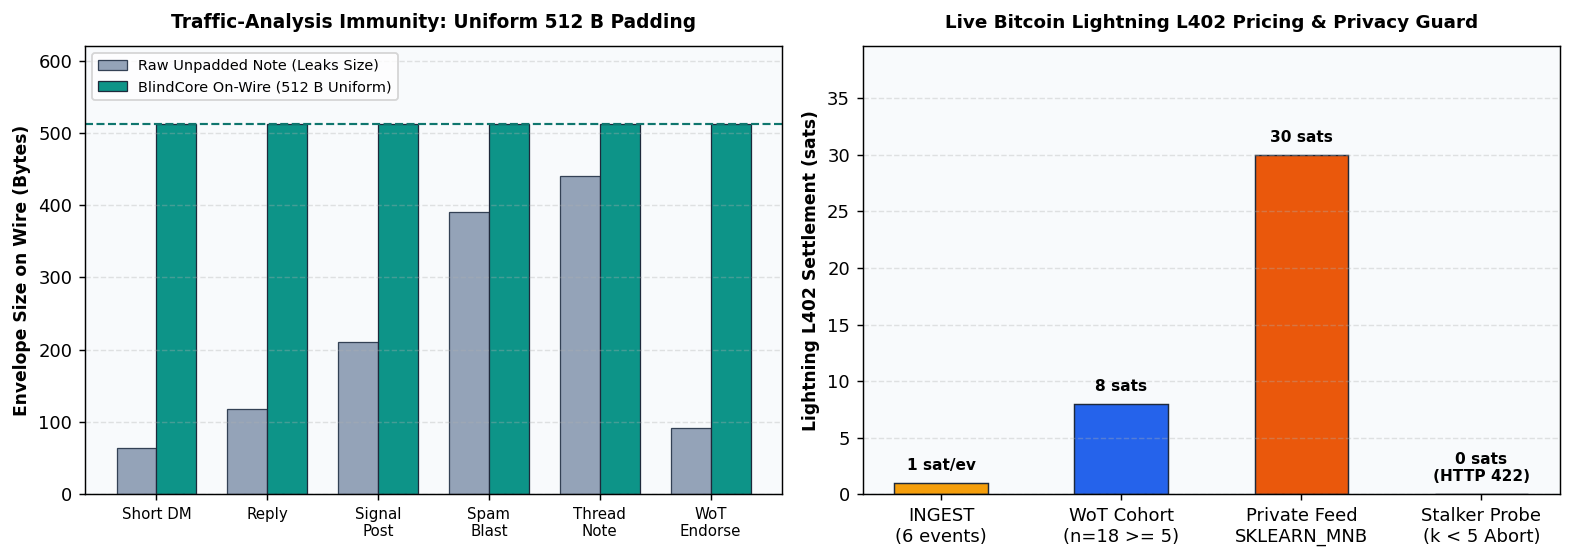

  GRANT & INVESTOR VERIFICATION BADGE : [ PASS ]
  Notebook 04 - Nostr Blind Relay & Private WoT (Bitcoin Lightning L402)
  Live Testnet 402: HTTP 402 | Padding: 512 B | Stalker Guard: HTTP 422
  L402 Settle Ref : 0x00d7083611aca02f296a159d2e139b532f0997f5f84be9d877ac7168df4aa2c2


In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4), dpi=130)
fig.patch.set_facecolor("white")

# Panel A: Traffic-Analysis Immunity - Raw Nostr Note Lengths vs Uniform 512 B Blind Relay Padding
notes = ["Short DM", "Reply", "Signal\nPost", "Spam\nBlast", "Thread\nNote", "WoT\nEndorse"]
raw_bytes = [64, 118, 210, 390, 440, 92]
padded_bytes = [sm["uniform_envelope_bytes"]] * len(notes)
x = np.arange(len(notes))
w = 0.36
ax1.bar(x - w / 2, raw_bytes, w, label="Raw Unpadded Note (Leaks Size)", color="#94A3B8", edgecolor="#334155", linewidth=0.7)
ax1.bar(x + w / 2, padded_bytes, w, label=f"BlindCore On-Wire ({sm['uniform_envelope_bytes']} B Uniform)", color="#0D9488", edgecolor="#1E293B", linewidth=0.7)
ax1.axhline(sm["uniform_envelope_bytes"], color="#0F766E", linestyle="--", linewidth=1.2)
ax1.set_xticks(x)
ax1.set_xticklabels(notes, fontsize=8.3)
ax1.set_ylim(0, 620)
ax1.set_ylabel("Envelope Size on Wire (Bytes)", fontsize=9.5, fontweight="bold")
ax1.set_title("Traffic-Analysis Immunity: Uniform 512 B Padding", fontsize=10.3, fontweight="bold", pad=10)
ax1.legend(loc="upper left", fontsize=8.0, frameon=True)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.set_facecolor("#F8FAFC")

# Panel B: Live Bitcoin Lightning L402 Micro-Pricing & Stalker Abort
ops_b = ["INGEST\n(6 events)", "WoT Cohort\n(n=18 >= 5)", "Private Feed\nSKLEARN_MNB", "Stalker Probe\n(k < 5 Abort)"]
sats_b = [1, wot["sats_paid"], feed["sats_paid"], 0]
colors_b = ["#F59E0B", "#2563EB", "#EA580C", "#7C3AED"]
bars_b = ax2.bar(ops_b, sats_b, color=colors_b, width=0.52, edgecolor="#1E293B", linewidth=0.8)
ax2.set_ylabel("Lightning L402 Settlement (sats)", fontsize=9.5, fontweight="bold")
ax2.set_title("Live Bitcoin Lightning L402 Pricing & Privacy Guard", fontsize=10.2, fontweight="bold", pad=10)
ax2.set_ylim(0, max(sats_b) * 1.32)
ax2.grid(axis="y", linestyle="--", alpha=0.35)
ax2.set_facecolor("#F8FAFC")
labels_top = ["1 sat/ev", f"{wot['sats_paid']} sats", f"{feed['sats_paid']} sats", f"0 sats\n(HTTP {stalker['http_status']})"]
for bar, lbl in zip(bars_b, labels_top):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.9,
        lbl,
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
    )

import io
from IPython.display import Image, display

plt.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=130, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(data=buf.getvalue()))

print("==========================================================================")
print("  GRANT & INVESTOR VERIFICATION BADGE : [ PASS ]")
print("  Notebook 04 - Nostr Blind Relay & Private WoT (Bitcoin Lightning L402)")
print(f"  Live Testnet 402: HTTP {probe_status} | Padding: {sm['uniform_envelope_bytes']} B | Stalker Guard: HTTP {stalker['http_status']}")
print(f"  L402 Settle Ref : {sp['settle_digest']}")
print("==========================================================================")
